# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [24]:
import pandas as pd

flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")


Display the first five rows of the DataFrame.


In [25]:
flights.head()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [26]:
flights.tail()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [27]:
flights.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer: There are 5,000 rows. Each row is one flight.


Count the missing values in every feature.


In [28]:
flights.isnull().sum()


airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | str | Categorical | 0 |
| `origin_city` | str | Categorical | 0 |
| `destination_city` | str | Categorical | 0 |
| `distance_miles` | int64 | Quantitative | 0 |
| `arrival_delay_minutes` | int64 | Quantitative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [29]:
destination_counts = flights["destination_city"].value_counts()
destination_counts


destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


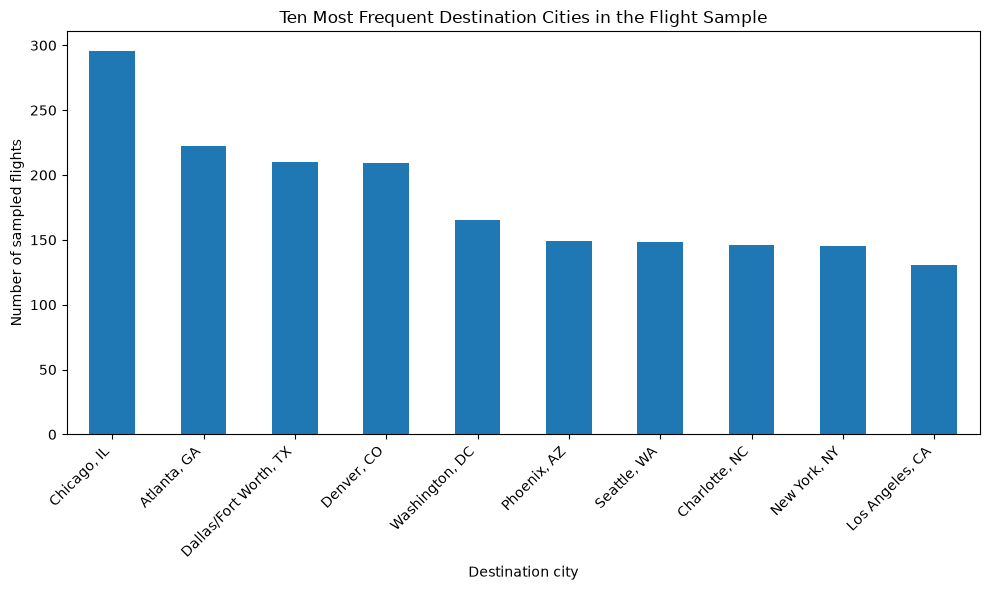

In [30]:
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar", figsize=(10, 6))
plt.title("Ten Most Frequent Destination Cities in the Flight Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of sampled flights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Which destination city is most common in the sample?**

Your answer: Chicago, IL, with 296 flights.


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


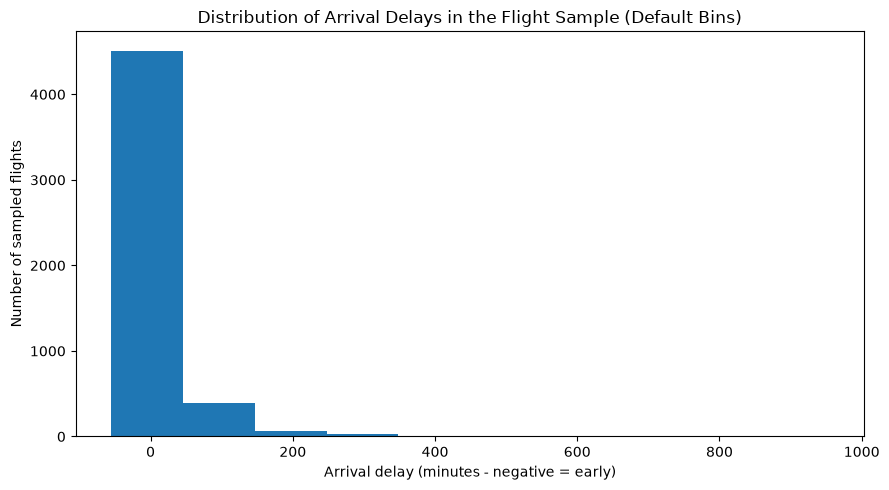

In [31]:
flights["arrival_delay_minutes"].plot(kind="hist", figsize=(9, 5))
plt.title("Distribution of Arrival Delays in the Flight Sample (Default Bins)")
plt.xlabel("Arrival delay (minutes - negative = early)")
plt.ylabel("Number of sampled flights")
plt.tight_layout()
plt.show()


**Approximately what arrival-delay value appears most common?**

Your answer: Around 0 minutes. The tallest bar covers about -55 to 46 minutes, so the chart is too broad to give an exact value.


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: About -50 to 950 minutes, a range of roughly 1,000 minutes.


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer: It is right-skewed. Most flights arrived early or had smaller delays, but a few very long delays stretch the chart to the right.


Display a numerical summary of `arrival_delay_minutes`.


In [32]:
flights["arrival_delay_minutes"].describe()


count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [33]:
flights["arrival_delay_minutes"].mode()


0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: The mode is -8 minutes, or 8 minutes early. That is close to the estimate of 0 minutes. The chart's wide bars make it hard to estimate an exact value.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: They were close. The actual minimum is -55 minutes and the maximum is 953 minutes, compared with the estimates of -50 and 950.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean is higher. It is about 6.10 minutes, while the median is -6 minutes.


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: A few very long delays pull the mean up. They affect the median less, which is why the mean is higher in this right-skewed chart.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


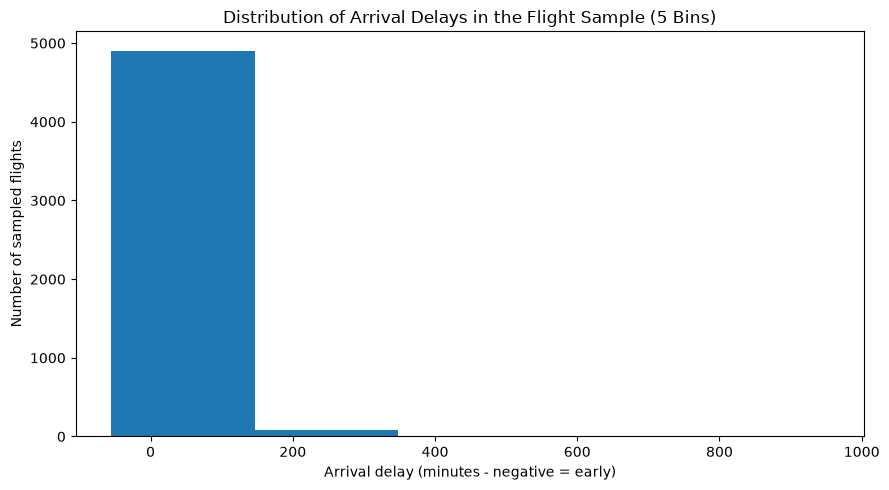

In [34]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=5, figsize=(9, 5))
plt.title("Distribution of Arrival Delays in the Flight Sample (5 Bins)")
plt.xlabel("Arrival delay (minutes - negative = early)")
plt.ylabel("Number of sampled flights")
plt.tight_layout()
plt.show()


Re-create the arrival-delay histogram using exactly 25 bins.


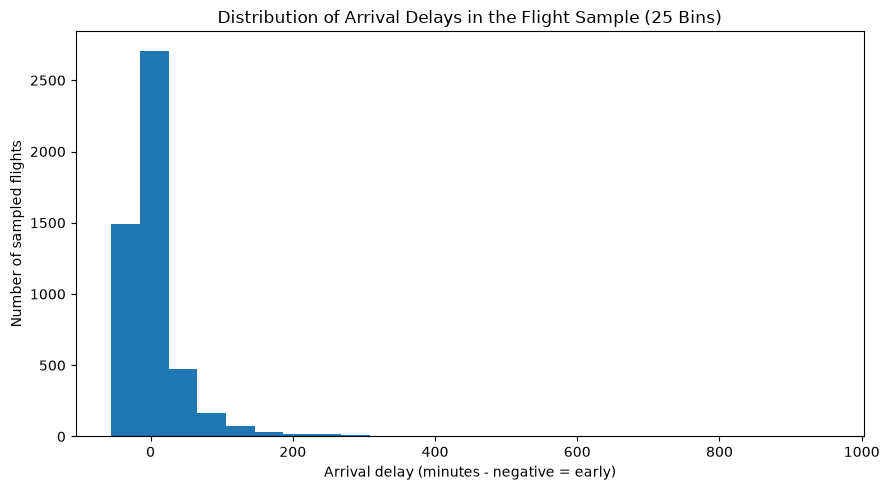

In [35]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=25, figsize=(9, 5))
plt.title("Distribution of Arrival Delays in the Flight Sample (25 Bins)")
plt.xlabel("Arrival delay (minutes - negative = early)")
plt.ylabel("Number of sampled flights")
plt.tight_layout()
plt.show()


**What changed when the number of bins was reduced to 5?**

Your answer: The bars got wider and hid more detail. The first bar now holds 4,905 of the 5,000 flights, mixing early arrivals with delays up to about 147 minutes.


**What changed when the number of bins was increased to 25?**

Your answer: The bars got narrower and show more detail near 0 minutes. The tallest bar covers about -15 to 26 minutes. A few long delays still stretch out to the right.


**Which bin setting communicates the distribution most clearly?**

Your answer: I would use 25 bins. It shows more detail near 0 minutes without cutting off the long delays. Five bins hides too much detail.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


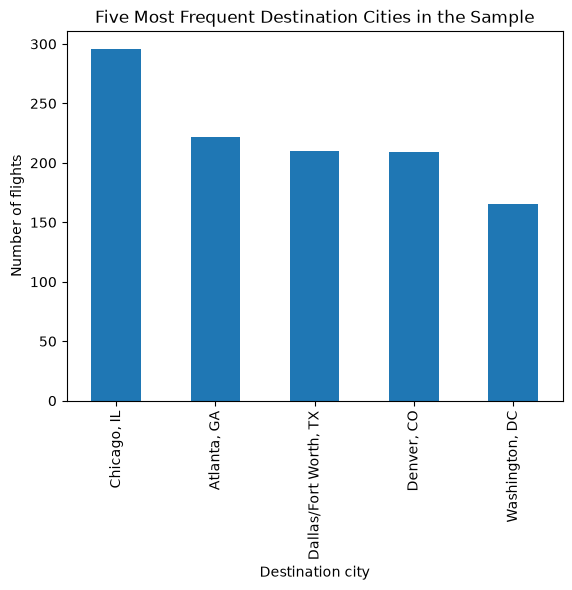

In [36]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


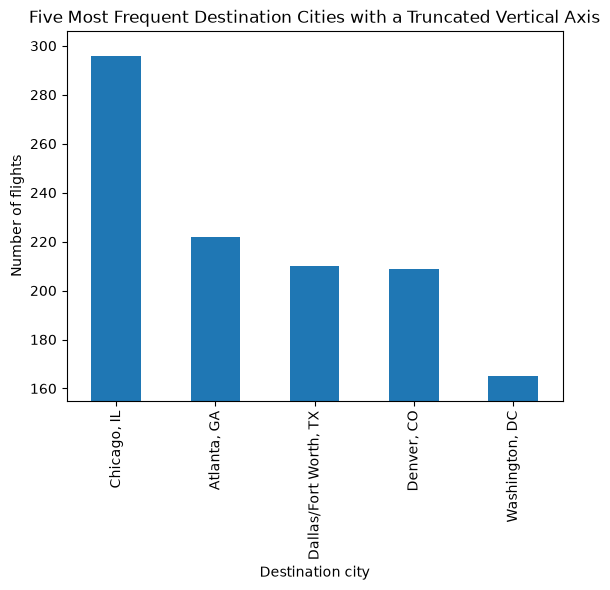

In [37]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer: Cutting off the bottom of the axis makes the differences look much bigger. The axis starts at 155 instead of 0, so Chicago's bar looks far larger than Washington's even though its count is less than twice as high.


**Which chart communicates the counts more honestly?**

Your answer: The first chart. Its axis starts at 0, so the bar heights show the differences fairly.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: May 2026.


**Which flights were eligible to be included in the sample?**

Your answer: Domestic flights that finished without being diverted and had values for all five columns.


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled flights, diverted flights, and any records missing a value in the five columns.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No. Rows with missing values were removed before the sample was picked.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: Those flights were left out of the sample. We cannot use this sample to describe flights it does not include.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: A bar chart. There are 13 airlines, and comparing bar heights is easier than comparing 13 pie slices.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: A pie chart. There are only three groups: early, on time, and delayed. Each flight belongs to one group, so labeled slices can show each group's percentage of all 5,000 flights.


**Which chart would you use to show the distribution of flight distances?**

Your answer: A histogram. Distance is measured in miles, and the bars show how many flights fall into each distance range.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: I used the **Iris Plants Database** by R. A. Fisher from the UCI Machine Learning Repository. Each row is one iris plant, with four flower measurements in centimeters and its species. There are 150 plants, with 50 from each of three species. The source refers to Fisher's 1936 work, but it does not give the exact collection dates or locations.

- Dataset: [UCI Iris](https://archive.ics.uci.edu/dataset/53/iris)
- Original comma-separated data: [iris.data](https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data)
- Data dictionary: [iris.names, Attribute Information](https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.names)
- Citation: Fisher, R. (1936). *Iris* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C56C76. Licensed CC BY 4.0.

The downloaded file had no column names, so I added them and saved it as `data/iris.csv`. The measurement values are unchanged. UCI notes that some values differ from Fisher's article. I kept the values from the downloaded file.


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [38]:
iris_df = pd.read_csv("data/iris.csv")

display(iris_df.head())
print("Shape (rows, columns):", iris_df.shape)
iris_df.info()
display(iris_df.isnull().sum())


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Shape (rows, columns): (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| `sepal_length_cm` | Sepal length in centimeters | Quantitative | float64 | 0 |
| `sepal_width_cm` | Sepal width in centimeters | Quantitative | float64 | 0 |
| `petal_length_cm` | Petal length in centimeters | Quantitative | float64 | 0 |
| `petal_width_cm` | Petal width in centimeters | Quantitative | float64 | 0 |
| `species` | Iris class: Iris-setosa, Iris-versicolor, or Iris-virginica | Categorical | str | 0 |

**Missing-value codes or other data preparation, if applicable:**

Your answer: The source says there are no missing values, and the code shows 0 for every column. No special missing-value codes are listed. No rows were removed or missing values filled in. I named the class column `species`. There are no ID or date/time columns.


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


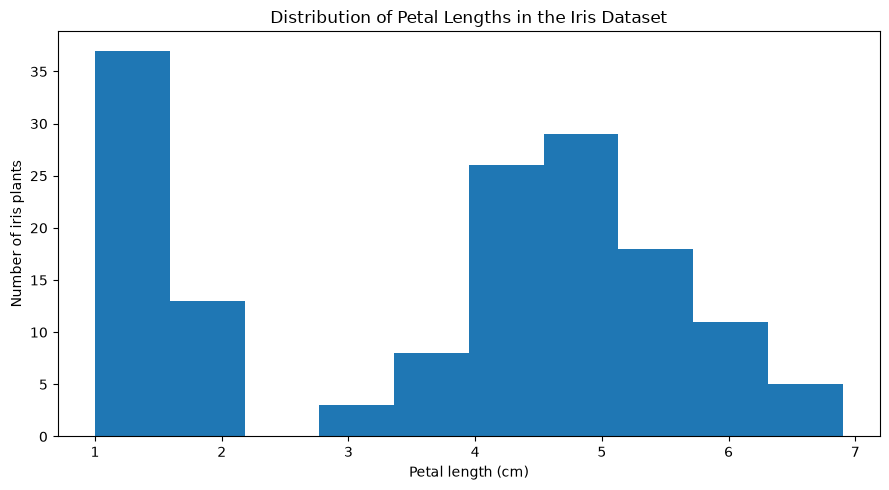

In [39]:
iris_df["petal_length_cm"].plot(kind="hist", bins=10, figsize=(9, 5))
plt.title("Distribution of Petal Lengths in the Iris Dataset")
plt.xlabel("Petal length (cm)")
plt.ylabel("Number of iris plants")
plt.tight_layout()
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose petal length in centimeters. A histogram shows how many plants fall into each length range. All 150 plants are included, with no rows left out.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation: Petal lengths range from about 1.0 to 6.9 cm. There is one group around 1 to 2 cm and another around 3 to 7 cm, with a gap between them. This describes the plants in this file, not all iris plants.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

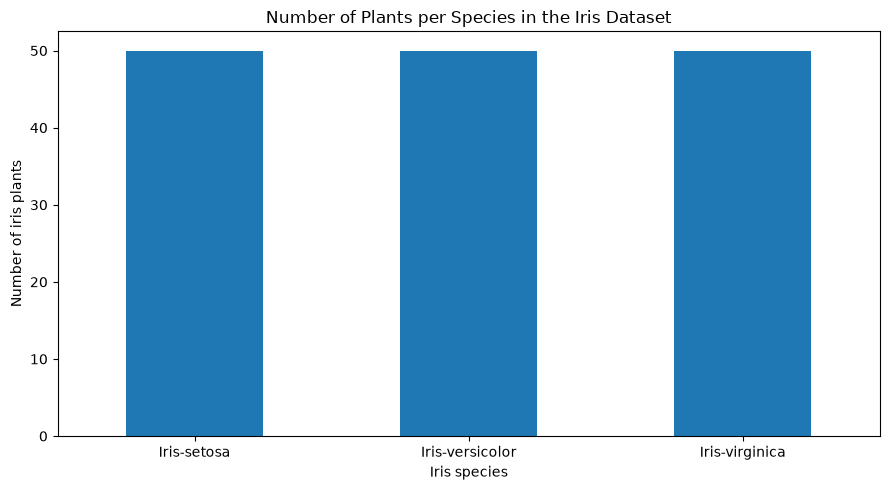

In [40]:
iris_species_counts = iris_df["species"].value_counts().sort_index()
display(iris_species_counts)

iris_species_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Number of Plants per Species in the Iris Dataset")
plt.xlabel("Iris species")
plt.ylabel("Number of iris plants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose species. A bar chart makes it easy to compare the counts for the three species. All 150 plants and all three species are included. The bars show counts, not percentages.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation: Each species has 50 plants, so all three bars are the same height. None is more common in this file. That does not mean they are equally common in nature.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:

- **Tool used:** OpenAI ChatGPT.
- **What I asked it to help with:** I asked it to analyze my work once I was finished, it found a couple of charts werent displaying correctly.
- **One suggestion I checked against my code, chart, or output:** It suggested that some of my charts were not displaying the intended data correctly, so I compared the charts with my code and output.
- **What I accepted, modified, or rejected, and why:** I accepted the suggestions that matched the issues I found in my charts and corrected them. I rejected or modified anything that did not match my actual code or output.

## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
